Objetivo: Implementar un red neuronal LeNet5 empleando keras e implementar una red neuronal  VGG.  




1. Importar las librerias:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from tensorflow import keras
import math

2. Cargar datos de entrenamiento y testeo.

In [2]:
(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()

3. Normallizar los datos.

In [3]:
np.shape(X_train)

(60000, 28, 28)

In [4]:
np.shape(X_test)

(10000, 28, 28)

In [5]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [6]:
len(y_train)

60000

In [7]:
N_train = X_train.reshape(60000*28*28)

mu = np.average(N_train)

sigma = np.std(N_train) 


X_train_N = (X_train - mu) / sigma

4. Realizar una visualización de 20 imagenes aproximadamente, puede emplear el comando imshow con cmap= binary.

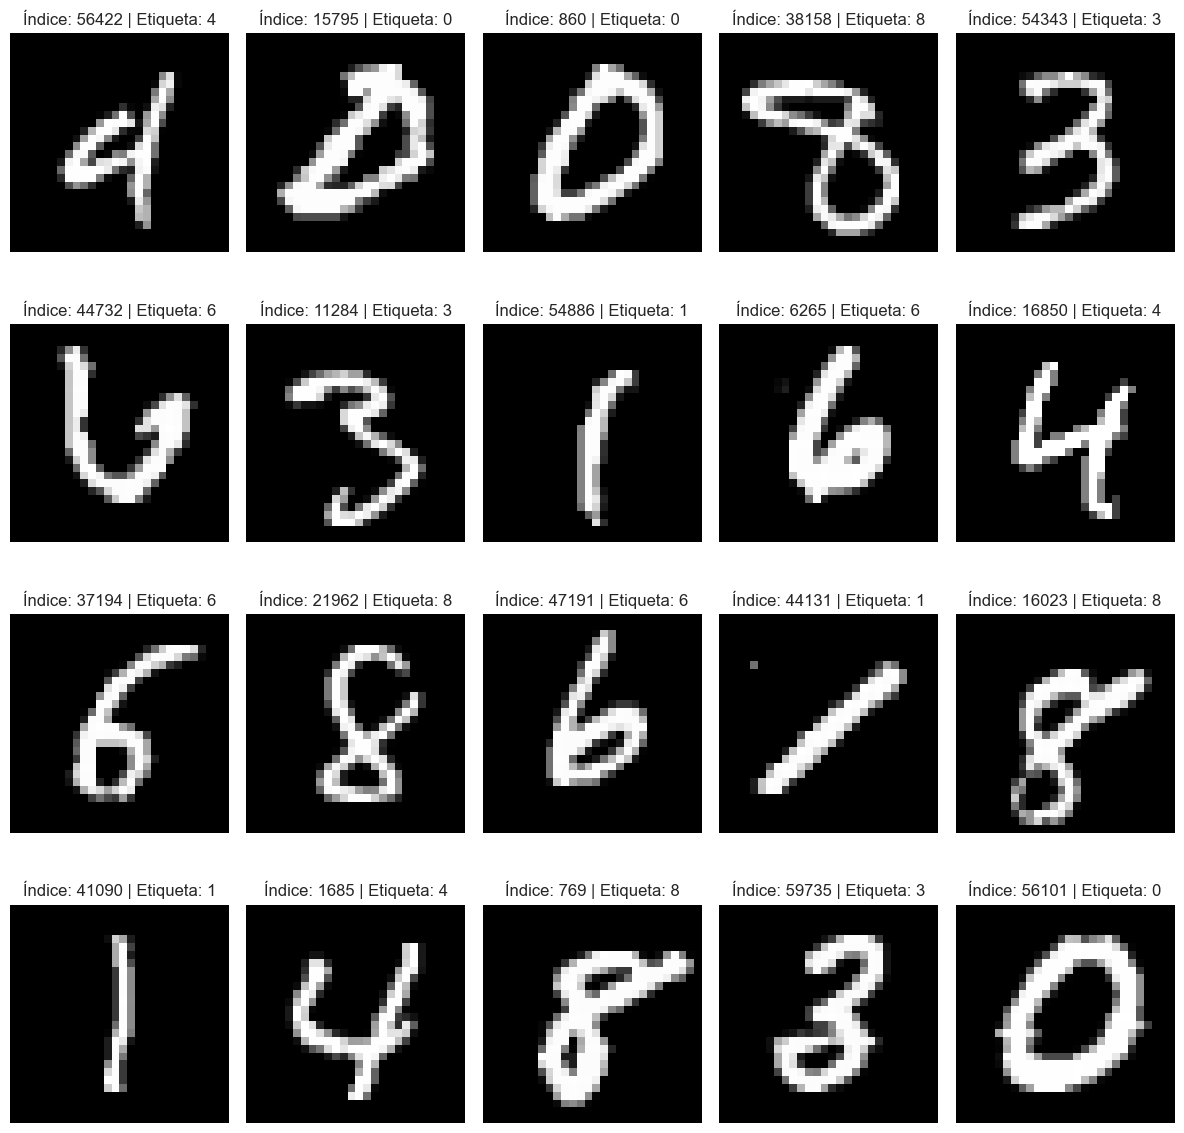

In [8]:
import numpy as np

np.random.seed(42)

index = np.random.randint(0, 60000, size=20)

filas = math.ceil(len(index) / 5)
fig, ax = plt.subplots(filas, 5, figsize=(12, 3 * filas))
ax = ax.flatten()

for i, idx in enumerate(index):
    ax[i].imshow(X_train[idx].reshape(28, 28), cmap="gray")
    ax[i].set_title(f"Índice: {idx} | Etiqueta: {y_train[idx]}")
    ax[i].axis("off")

for i in range(len(index), len(ax)):
    ax[i].axis("off")

plt.tight_layout()
plt.show()


5. Implementar en keras, la red Letnet5, la arquitectura de la red es la siguiente:

![img](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/LeNet5.png?raw=true)


Par la implementación, se recomienda construir un modelo secuencial.


```python
keras.backend.clear_session()
models=keras.models.Sequential([...])

```

algunos parámetros que pueden ser pasados dentro de los tres puntos anteriores son:


```python
keras.layers.MaxPool2D,
keras.layers.Conv2D,
keras.layers.Flatten,
keras.layers.Dense
```

Revisa la documentación para pasar los valores adecuados.

s es el stride e indica el nuemro de pasos que avanza la lupa. f=2 y s=2 avg pool captura particiona las matrices en arrays de fxf = 4 cada s= 2 pasos, y en cada matriz de fxf le saca unn solo numero asociado que es el promedio de los cuatro valores. En la primera convolucion convolucion, el stride s=1 indica que se dan pasos de a uno, y en cada paso se selcciona una matriz de 5x5 y se le aplican cinco filtros distintos. En la segunda convolucion se aplican 16 fitros de tamaño 5x5 y en pasos de s=1.

In [10]:
model=keras.models.Sequential([
                               keras.layers.Conv2D(6,kernel_size=5,strides=1,padding='valid',activation='relu',kernel_initializer='he_uniform',input_shape=(28,28,1)),
                               keras.layers.MaxPool2D(pool_size=2, strides=2),
                               keras.layers.Conv2D(16,kernel_size=5,strides=1,padding='valid',activation='relu',kernel_initializer='he_uniform'),
                               keras.layers.MaxPool2D(pool_size=2, strides=2),
                               keras.layers.Flatten(),
                               keras.layers.Dense(256,activation='relu',kernel_initializer='he_uniform'),
                               keras.layers.Dense(84,activation='relu',kernel_initializer='he_uniform'),
                               keras.layers.Dense(10,activation='softmax')
                               ])

6. Revisa el modelo que acabaste de construir.

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 24, 24, 6)           │             156 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 12, 12, 6)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 8, 8, 16)            │           2,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 4, 4, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 84)                  │          21,588 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             850 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 90,802 (354.70 KB)

 Trainable params: 90,802 (354.70 KB)

 Non-trainable params: 0 (0.00 B)

7. Vamos a utlizar un optimizador de Adams,  El optimizador de Adam (Adaptive Moment Estimation) combina las ventajas de los algoritmos RMSProp y Momentum para mejorar el proceso de aprendizaje de un modelo. Al igual que Momentum, Adam utiliza una estimación del momento y de la magnitud de los gradientes  para actualizar los parámetros del modelo en cada iteración. Sin embargo, en lugar de utilizar una tasa de aprendizaje constante para todos los parámetros, Adam adapta la tasa de aprendizaje de cada parámetro individualmente en función de su estimación del momento y de la magnitud del gradiente. Esto permite que el modelo se ajuste de manera más eficiente y efectiva a los datos de entrenamiento, lo que puede llevar a una mayor precisión de la predicción en comparación con otros métodos de optimización.


El optimizador de Adam es un algoritmo de optimización basado en gradientes de primer orden que utiliza estimaciones adaptativas de momentos de primer y segundo orden. El algoritmo se puede describir de la siguiente forma :

$$
\begin{aligned}
& \text{Inicializar:} \quad \theta_0, \alpha, \beta_1, \beta_2, \epsilon \\
& \text{Para cada iteración } t = 1, 2, \dots \\
& \quad \text{Obtener el gradiente:} \quad g_t = \nabla_\theta J(\theta_{t-1}) \\
& \quad \text{Actualizar los momentos de primer orden:} \quad m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \\
& \quad \text{Actualizar los momentos de segundo orden:} \quad v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \\
& \quad \text{Corregir el sesgo de los momentos de primer orden:} \quad \hat{m}_t = \frac{m_t}{1 - \beta_1^t} \\
& \quad \text{Corregir el sesgo de los momentos de segundo orden:} \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \\
& \quad \text{Actualizar los parámetros:} \quad \theta_t = \theta_{t-1} - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}
\end{aligned}
$$

Donde $\theta$ son los parámetros del modelo, $\alpha$ es la tasa de aprendizaje, $\beta_1$ y $\beta_2$ son los factores de decaimiento de los momentos, $\epsilon$ es un término de suavizado para evitar la división por cero, $J$ es la función objetivo, $g_t$ es el gradiente en la iteración $t$, $m_t$ y $v_t$ son los momentos de primer y segundo orden respectivamente, y $\hat{m}_t$ y $\hat{v}_t$ son las correcciones de sesgo de los momentos.




emplea el siguiente compilador del modelo
```python
 model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
 ```


In [12]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

8. Realiza el fit del modelo, emplea GPU, para ello cambia la configuración de collaboratory para que tu modelo se ejecute un poco mas rápido.

- Loss: es la medida del error que comete el modelo al predecir las etiquetas de los datos de entrenamiento. Es una función que se quiere minimizar durante el entrenamiento. Un valor bajo de loss indica que el modelo se ajusta bien a los datos de entrenamiento.
- Accuracy: es la medida del porcentaje de predicciones correctas que hace el modelo sobre los datos de entrenamiento. Es una métrica que se quiere maximizar durante el entrenamiento. Un valor alto de accuracy indica que el modelo clasifica bien los datos de entrenamiento.
- Val_loss: es la medida del error que comete el modelo al predecir las etiquetas de los datos de validación. Los datos de validación son un subconjunto de los datos de entrenamiento que se reservan para evaluar el rendimiento del modelo durante el entrenamiento. Un valor bajo de val_loss indica que el modelo se generaliza bien a los datos de validación.
- Val_accuracy: es la medida del porcentaje de predicciones correctas que hace el modelo sobre los datos de validación. Un valor alto de val_accuracy indica que el modelo clasifica bien los datos de validación.


In [13]:
import tensorflow as tf

In [14]:
print("GPU disponibles:", tf.config.list_physical_devices('GPU'))

GPU disponibles: []


In [15]:
history = model.fit(X_train,y_train,epochs=10,validation_split=0.3)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 25s 18ms/step - accuracy: 0.8267 - loss: 3.1286 - val_accuracy: 0.9013 - val_loss: 0.4286
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 38s 15ms/step - accuracy: 0.9282 - loss: 0.2878 - val_accuracy: 0.9407 - val_loss: 0.2636
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.9515 - loss: 0.1834 - val_accuracy: 0.9494 - val_loss: 0.2173
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.9608 - loss: 0.1437 - val_accuracy: 0.9573 - val_loss: 0.1746
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 42s 17ms/step - accuracy: 0.9676 - loss: 0.1163 - val_accuracy: 0.9658 - val_loss: 0.1402
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.9721 - loss: 0.1013 - val_accuracy: 0.9612 - val_loss: 0.1569
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.9765 - loss: 0.0821 - val_accuracy: 0.9676 - val_loss: 0.1402
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - accuracy: 0.9813 -

In [16]:
np.shape(y_train)

(60000,)

9. Realizar la predicción:

In [17]:
q=model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


10. Muestra los valores de q y determina que numero se esta prediciendo.

In [18]:
np.shape(q)

(10000, 10)

In [22]:
q[0]

array([4.1673076e-12, 3.7262632e-07, 2.5877667e-09, 1.1771883e-09,
       4.4695541e-09, 2.8501230e-13, 1.7631151e-17, 9.9999785e-01,
       4.2515144e-11, 1.7577843e-06], dtype=float32)

In [19]:
prediccion = np.argmax(q, axis = 1) 

    

In [20]:
prediccion

array([7, 2, 1, ..., 4, 5, 6])

In [23]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

In [21]:
a = prediccion == y_test

In [34]:
len(y_test)

10000

In [32]:
s = (a == True).sum() / len(prediccion)

In [33]:
s

np.float64(0.975)

prediccion = np.argmax(q, axis = 1)
a = prediccion == y_test
s = (a == True).sum() / len(prediccion)

11. Graficar la convergencia del modelo.

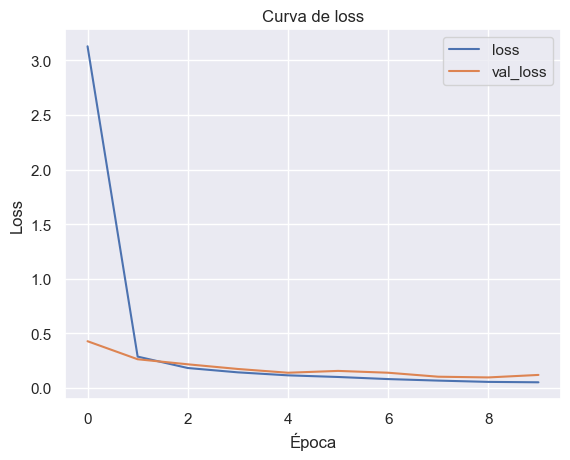

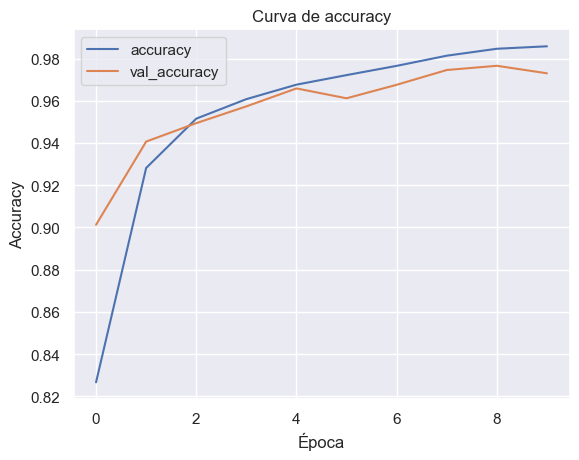

In [35]:
import matplotlib.pyplot as plt
# Graficar la curva de loss
plt.plot (history.history ['loss'], label='loss')
plt.plot (history.history ['val_loss'], label='val_loss')
plt.title ('Curva de loss')
plt.xlabel ('Época')
plt.ylabel ('Loss')
plt.legend ()
plt.show ()
# Graficar la curva de accuracy
plt.plot (history.history ['accuracy'], label='accuracy')
plt.plot (history.history ['val_accuracy'], label='val_accuracy')
plt.title ('Curva de accuracy')
plt.xlabel ('Época')
plt.ylabel ('Accuracy')
plt.legend ()
plt.show ()

12. Una forma alterna de implementar el modelo puede ser dada de la siguiente forma:

```python
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.losses import sparse_categorical_crossentropy
from tensorflow.keras.optimizers import Adam

X_train = X_train.reshape(60000,28,28,1)
X_test = X_test.reshape(10000,28,28,1)
input_shape = (28,28,1)
model = Sequential()
model.add(Conv2D(6, kernel_size=(5, 5), activation='relu', input_shape=input_shape))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model.add(Conv2D(16, kernel_size=(5, 5), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(84, activation='relu'))
model.add(Dense(10, actition='softmax'))


´´´

13. Emplea la arquitectura anterior para el  
  el dataset cifar100,  empleando BatchNormalization y dropout.


- BatchNormalization es una técnica que se usa para acelerar y estabilizar el entrenamiento de las redes neuronales artificiales, mediante la normalización de las entradas de cada capa, re-centrando y re-escalando los datos.

  BatchNormalization se aplica justo antes de la función de activación de cada capa, y consiste en centrar y normalizar cada mini-lote con una media y una desviación estándar calculadas con los datos del mini-lote, y luego re-escalar y desplazar los datos de nuevo con parámetros aprendidos por la red durante el entrenamiento. Estos parámetros permiten que la red se adapte a la distribución óptima de las activaciones para cada capa. Además, al introducir cierto ruido en los datos, BatchNormalization actúa como una regularización y ayuda a reducir el sobreajuste.


- El dropout es una técnica de regularización para reducir el sobreajuste en redes neuronales artificiales. El sobreajuste ocurre cuando el modelo se ajusta demasiado a los datos de entrenamiento y pierde capacidad de generalizar a nuevos datos. El dropout consiste en eliminar aleatoriamente algunas neuronas de la red durante el entrenamiento, lo que hace que el modelo sea más robusto y menos dependiente de ciertas conexiones. El dropout se puede interpretar como una forma de promediar varios modelos más pequeños y diferentes, lo que mejora el rendimiento final.

  El dropout se aplica a cada capa de la red, especificando una probabilidad de mantener cada neurona activa. Por ejemplo, si se usa un dropout de 0.2, significa que el 20% de las neuronas se desactivarán en cada iteración del entrenamiento. El dropout solo se usa durante el entrenamiento, no durante la inferencia o la evaluación. El dropout se puede combinar con otras técnicas de regularización, como la normalización de pesos o la normalización por lotes.




```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from tensorflow import keras


(train_image, train_label) , (test_image, test_label) = keras.datasets.cifar100.load_data()


plt.imshow(train_image[30])
plt.axis('off')
```

intenta agregar, lineas como las siguientes en los lugares mas estrategicos:


```python
keras.layers.Dropout(0.2),
keras.layers.BatchNormalization()

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.losses import sparse_categorical_crossentropy
from tensorflow.keras.optimizers import Adam

In [66]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Dropout

In [71]:

input_shape = (32,32,3)
model2 = Sequential()
model2.add(Conv2D(6, kernel_size=(5, 5), activation='relu', input_shape=input_shape))
model2.add(BatchNormalization())
model2.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model2.add(Conv2D(16, kernel_size=(5, 5), activation='relu'))
model2.add(BatchNormalization())
model2.add(MaxPooling2D(pool_size=(2, 2), strides=2))
#model.add(Dropout(0.25))
model2.add(Flatten())
model2.add(Dense(256, activation='relu'))
model2.add(BatchNormalization())
model2.add(Dropout(0.2))
model2.add(Dense(84, activation='relu'))
model2.add(BatchNormalization())
model2.add(Dropout(0.2))
model2.add(Dense(100, activation='softmax'))

14. Emplea el siguiente compilador:

El optimizador de NAdam (Nesterov-accelerated Adaptive Moment Estimation) es una variante de Adam que incorpora el método de Nesterov, que consiste en utilizar una predicción de la posición futura de los parámetros para calcular el gradiente, en lugar de la posición actual. Esto hace que el algoritmo sea más sensible a los cambios de dirección del gradiente y evite oscilaciones innecesarias. NAdam también modifica la forma de calcular el momento y la magnitud del gradiente, usando una media móvil exponencial sesgada hacia cero en lugar de una media móvil exponencial simple.


```python
model.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
```

El número de épocas que se necesita para entrenar una red neuronal depende de varios factores, como el tamaño de los datos, la complejidad del modelo, la función de pérdida, el algoritmo de optimización, la tasa de aprendizaje, etc. No hay una regla fija para elegir el número de épocas, pero se puede usar el criterio de parada temprana, que consiste en monitorear el error de validación y detener el entrenamiento cuando este empiece a aumentar, lo que indica un sobreajuste del modelo.

In [72]:
model2.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

15. Emplea early_stooping y realiza el fit



```python
early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
```

El parámetro patience=5 indica el número de épocas sin mejora después de las cuales se detendrá el entrenamiento. El parámetro restore_best_weights=True indica que se restaurarán los pesos del modelo desde la época con el mejor valor de la métrica monitoreada. Esto puede ayudar a evitar el sobreajuste y mejorar el rendimiento del modelo



```python
history = model.fit(train_image, train_label, epochs=30, validation_split=0.2 , batch_size=64, callbacks=[early_stopping])
```

In [45]:
from tensorflow.keras.datasets import cifar100

In [55]:
# Cargar los datos de entrenamiento y prueba
(X_train_cifar, y_train_cifar), (X_test_cifar, y_test_cifar) = cifar100.load_data(label_mode='fine')

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 921s 5us/step


In [58]:
# Verificar las dimensiones
print(f"X_train: {X_train_cifar.shape}")  # (50000, 32, 32, 3)
print(f"X_test:  {X_test_cifar.shape}")   # (10000, 32, 32, 3)

X_train: (50000, 32, 32, 3)
X_test:  (10000, 32, 32, 3)


In [59]:
X_train_cifar = X_train_cifar.astype('float32') / 255.0
X_test_cifar = X_test_cifar.astype('float32') / 255.0

In [61]:
from tensorflow.keras.callbacks import EarlyStopping

In [73]:
early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

In [74]:
history2 = model2.fit(X_train_cifar, y_train_cifar, epochs=30, validation_split=0.2 , batch_size=64, callbacks=[early_stopping])

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - accuracy: 0.0808 - loss: 4.1117 - val_accuracy: 0.1322 - val_loss: 3.7174
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.1562 - loss: 3.5889 - val_accuracy: 0.1712 - val_loss: 3.5034
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - accuracy: 0.1923 - loss: 3.3580 - val_accuracy: 0.1861 - val_loss: 3.4296
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.2208 - loss: 3.2194 - val_accuracy: 0.2403 - val_loss: 3.1149
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.2414 - loss: 3.1174 - val_accuracy: 0.2130 - val_loss: 3.2593
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.2554 - loss: 3.0288 - val_accuracy: 0.2535 - val_loss: 3.0243
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.2616 - loss: 2.9772 - val_accuracy: 0.2675 - val_loss: 3.0051
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.2759 - loss: 2.9164 - 

In [78]:
q = model2.predict(X_test_cifar)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


In [79]:
len(q[0])

100

In [81]:
len(q)

10000

In [80]:
y_test_cifar


array([[49],
       [33],
       [72],
       ...,
       [51],
       [42],
       [70]])

In [84]:
y_test_cifar = y_test_cifar.reshape(10000)

In [85]:
prediccion = np.argmax(q, axis = 1)
a = prediccion == y_test
s = (a == True).sum() / len(prediccion)

In [86]:
s

np.float64(0.0129)

Ahora vamos a implementar una red VGG16, para ello puedes emplear la siguiente linea de código:


```python
from tensorflow import keras
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# Indian elephant
!wget https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg -O indian_elephant.jpg
# African elephant
!wget https://upload.wikimedia.org/wikipedia/commons/b/bf/African_Elephant_%28Loxodonta_africana%29_male_%2817289351322%29.jpg -O african_elephant.jpg
#!wget https://github.com/ssanchezgoe/diplomado_udea/blob/master/image/african_elephant_bull.jpg?raw=true -O african_elephant.jpg

# Choose the elephant to be classified
img_path = 'african_elephant.jpg'

img = mpimg.imread(img_path)
implot = plt.imshow(img)

print("Tamaño de la imagen:",img.shape)
```


```python
from keras.preprocessing import image

model = keras.applications.vgg16.VGG16(weights='imagenet', include_top=True)
model.summary()

```


```python
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)# Añadir una dimensión extra para el lote
x = keras.applications.vgg16.preprocess_input(x)

features = model.predict(x)

print("Prediction", keras.applications.vgg16.decode_predictions(features, top=3)[0])
```

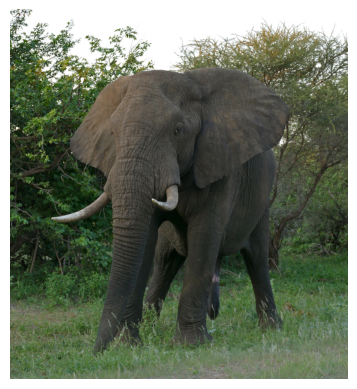

Tamaño de la imagen: (4000, 3648, 3)
553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 16s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 921ms/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
Prediction: [('n02504458', 'African_elephant', np.float32(0.9014321)), ('n01871265', 'tusker', np.float32(0.089663714)), ('n02504013', 'Indian_elephant', np.float32(0.008881044))]


In [89]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import urllib.request
from tensorflow import keras
from tensorflow.keras.preprocessing import image

# URLs de las imágenes
url_indian = "https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg"
url_african = "https://upload.wikimedia.org/wikipedia/commons/b/bf/African_Elephant_%28Loxodonta_africana%29_male_%2817289351322%29.jpg"

# Cabecera User-Agent para evitar el bloqueo HTTP de Wikimedia
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}

req_indian = urllib.request.Request(url_indian, headers=headers)
req_african = urllib.request.Request(url_african, headers=headers)

# Descargar las imágenes localmente
with urllib.request.urlopen(req_indian) as resp, open("indian_elephant.jpg", "wb") as f:
    f.write(resp.read())

with urllib.request.urlopen(req_african) as resp, open("african_elephant.jpg", "wb") as f:
    f.write(resp.read())

# Elegir la imagen a clasificar
img_path = 'african_elephant.jpg'

img = mpimg.imread(img_path)
plt.imshow(img)
plt.axis('off')
plt.show()

print("Tamaño de la imagen:", img.shape)

# Cargar VGG16 preentrenada en ImageNet
model3 = keras.applications.vgg16.VGG16(weights='imagenet', include_top=True)

# Preprocesar imagen para VGG16 (224x224)
img_prep = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img_prep)
x = np.expand_dims(x, axis=0)
x = keras.applications.vgg16.preprocess_input(x)

# Predicción
features = model3.predict(x)
print("Prediction:", keras.applications.vgg16.decode_predictions(features, top=3)[0])